# [실습] 분류 — 확률을 예측하고 선을 긋기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 3 실습. 1,000통으로 가입을 가장 많이 얻으려면?

**필수 머신러닝 · Chapter 3**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 현행 방법 만들기: 사람이 쓰는 선정 규칙 |
| Part 3 | 모델과 임계값 |
| Part 4 | 통화 예산 곡선과 결정 |

## 분석 의뢰서

> **의뢰 부서**: 은행 마케팅팀
> **목적**: 정기예금 상품 가입을 권유하는 전화 캠페인을 하려 한다. 가입할 가능성이 높은 고객에게 먼저 전화하고 싶다.
> **제약**: 콜센터가 이번 캠페인에 걸 수 있는 전화는 약 1,000통이다. 고객은 9,000명이 넘는다.
> **질문**: 누구에게 전화해야 가입을 가장 많이 얻을 수 있을까?

## 이 실습의 질문

> **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 그리고 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

Chapter 1, 2와 같은 순서로 진행합니다. 여러분이 먼저 마케팅팀 담당자처럼 **사람이 쓰는 선정 규칙**을 만들고, 그 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 마케팅팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

UCI Bank Marketing 데이터의 `bank-full.csv`(통화 45,211건)를 이 노트북과 같은 폴더에 두세요. 이 파일은 열을 쉼표가 아니라 세미콜론(`;`)으로 구분합니다.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

## 1-1. 데이터 불러오기

**[직접 작성]** `bank-full.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

구분자가 세미콜론이므로 `pd.read_csv("bank-full.csv", sep=";")`처럼 `sep`을 알려 줘야 합니다.
</details>

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
# metadata 
print(bank_marketing.metadata) 
  
# variable information 
print(bank_marketing.variables) 

{'uci_id': 222, 'name': 'Bank Marketing', 'repository_url': 'https://archive.ics.uci.edu/dataset/222/bank+marketing', 'data_url': 'https://archive.ics.uci.edu/static/public/222/data.csv', 'abstract': 'The data is related with direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe a term deposit (variable y).', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 45211, 'num_features': 16, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Occupation', 'Marital Status', 'Education Level'], 'target_col': ['y'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 2014, 'last_updated': 'Fri Aug 18 2023', 'dataset_doi': '10.24432/C5K306', 'creators': ['S. Moro', 'P. Rita', 'P. Cortez'], 'intro_paper': {'ID': 277, 'type': 'NATIVE', 'title': 'A data-driven approach to predict the s

In [3]:
# 1-1. 은행 마케팅 데이터프레임 불러오기
df = pd.concat([bank_marketing.data.features, bank_marketing.data.targets], axis=1)
print(df.shape)
df.head()

print(df.isna().sum())            # ucimlrepo 데이터: NaN 개수
print((df == 'unknown').sum())    # 0이면 NaN 방식

(45211, 17)
age                0
job              288
marital            0
education       1857
default            0
balance            0
housing            0
loan               0
contact        13020
day_of_week        0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome       36959
y                  0
dtype: int64
age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day_of_week    0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64


원본 데이터에는 통화 시간(`duration`)이라는 열이 있습니다. 이 실습에서는 **쓰지 않습니다.** 이유는 Chapter 4에서 다룹니다. **[제공]** 셀을 실행해 이 열을 제외하세요.

In [4]:
# [제공] 통화 시간 열 제외
df = df.drop(columns=["duration"])
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day_of_week', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


## 1-2. 맞히려는 값 만들기

결과 열 `y`는 "yes"/"no" 글자입니다. 모델이 다룰 수 있도록 0과 1로 바꿉니다.

**[직접 작성]** 가입(`yes`)이면 1, 아니면 0인 열 `target`을 `df`에 만들고, `target`의 값별 개수와 비율을 확인하세요.

<details><summary>힌트</summary>

`df["target"] = (df["y"] == "yes").astype(int)`, 비율은 `df["target"].value_counts(normalize=True)`.
</details>

In [5]:
# 1-2. 맞히려는 값 만들기
df["target"] = (df["y"] == "yes").astype(int)

# 값별 개수와 비율을 표로 정리
counts = df["target"].value_counts().sort_index()

summary = pd.DataFrame({
    "의미": ["미가입", "가입"],
    "개수": counts.values,
    "비율(%)": (counts / counts.sum() * 100).round(2).values,
}, index=pd.Index(counts.index, name="target"))

summary.style.format({"개수": "{:,}", "비율(%)": "{:.1f}%"})

,의미,개수,비율(%)
target,,,
0,미가입,"39,922",88.3%
1,가입,"5,289",11.7%


> **[판단]** "전부 미가입"이라고 답하는 방법의 정확도는 얼마인가요? 이 방법은 콜센터에 어떤 가치가 있을까요?
>
> 나의 답: 88.3%의 정확도를 보이지만 예상 가입자에게 마케팅을 해야하는 콜센터 입장에서는 전혀 가치가 없다.

## 1-3. 데이터의 결함 찾기

**[직접 작성]** 아래 두 가지를 확인하세요.

1. `pdays`(이전 캠페인 이후 경과일)가 `-1`인 행의 비율
2. 글자로 된 열마다 `"unknown"`이라는 값이 몇 개 있는지

<details><summary>힌트</summary>

비율은 `(df["pdays"] == -1).mean()`. `"unknown"`은 `df.select_dtypes("object")`로 글자 열만 고른 뒤 `(열 == "unknown").sum()`을 세면 됩니다. 글자 열이 아닌 `target` 같은 열은 건너뜁니다.
</details>

In [7]:
# 1-3. 데이터의 결함 찾기
# 1) pdays가 -1인 행의 비율
print("pdays == -1 비율:", round((df["pdays"] == -1).mean(), 4))

# 2) "unknown"을 NaN으로 바꾼 뒤 열별 결측 개수
df_nan = df.replace("unknown", np.nan)
na_counts = df_nan.isna().sum()
print(na_counts[na_counts > 0])

pdays == -1 비율: 0.8174
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64


> **[판단]** `pdays`의 −1은 어떤 뜻일까요? 이 열을 숫자 그대로 모델에 넣으면 어떤 문제가 생길까요?
>
> 나의 답: pdays의 −1은 "이전 캠페인에서 이 고객에게 한 번도 연락하지 않았다"는 뜻입니다. 실제 경과일이 아니라 연락 이력이 없다는 표시입니다. 이 값을 숫자 그대로 넣으면 모델은 −1을 "가장 최근에 연락한 고객"처럼 받아들입니다. 실제로는 연락 이력이 없는 고객인데, 값의 크기 때문에 순서가 왜곡됩니다. 그래서 −1은 별도의 표시(예: "연락 없음" 여부를 나타내는 열)로 따로 빼거나 결측처럼 다루는 편이 낫습니다. 전체의 81.7%가 −1이라 이 왜곡이 결과에 크게 영향을 줍니다.

> **[판단]** `unknown`이 많은 열(`contact`, `poutcome`)은 어떻게 다루겠습니까? (예: 그대로 하나의 값으로 둔다 / 뺀다) 선택과 이유를 적으세요.
>
> 나의 답: unknown을 뺏지 않고 그대로 하나의 값(범주)으로 두겠습니다. 이유는 두 가지입니다. 첫째, poutcome은 unknown이 36,959개로 전체의 약 82%라서 열을 빼면 이전 캠페인 결과라는 정보가 통째로 사라집니다. 둘째, unknown이 "정보가 없다"는 뜻이 아니라 "이전 캠페인에 참여하지 않았다"는 의미를 담고 있을 수 있습니다. 실제로 poutcome의 unknown 개수(36,959)와 pdays의 −1 개수(36,954)가 거의 같아서, 같은 고객들을 가리키는 것으로 보입니다. contact도 13,020개(약 29%)라 행을 지우면 데이터가 크게 줄어듭니다. 그래서 unknown을 하나의 범주로 두고 원-핫 인코딩하는 쪽을 택하겠습니다.

## 1-4. 평가용 데이터 먼저 떼어 두기

Chapter 1, 2와 같은 원칙입니다. 이후의 탐색과 규칙 만들기는 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`, 그리고 가입 비율이 두 쪽에 같게 `target`으로 `stratify`합니다.

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])`
</details>

In [8]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df["target"]
)

print(len(train_df), len(test_df))

36168 9043


> **[판단]** 왜 가입 비율이 두 쪽에 같도록(`stratify`) 나눌까요? 가입이 11.7%뿐인 데이터를 그냥 무작위로 나누면 어떤 일이 생길 수 있나요?
>
> 나의 답:  가입 비율을 두 쪽에 같게 나누는 이유는 평가용 데이터가 전체 고객의 특성을 대표하도록 하기 위해서입니다. 가입이 11.7%뿐이라 무작위로 나누면 평가용 데이터에 가입 고객이 너무 적거나 많게 들어갈 수 있습니다. 예를 들어 가입이 적게 들어간 평가용 데이터에서 모델을 채점하면 점수가 실제보다 낮거나 불안정하게 나옵니다. 또 학습용과 평가용의 비율이 달라지면 학습 때 본 패턴과 평가 때의 패턴이 달라져서 공정한 비교가 어렵습니다. stratify로 두 쪽의 가입 비율을 같게 맞추면 이런 편차를 줄이고, 결과를 같은 기준으로 비교할 수 있습니다.

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 끝낸 사람은 실행하지 않아도 됩니다.

In [ ]:
# [제공] 체크포인트: 1-4까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("bank-full.csv", sep=";").drop(columns=["duration"])
df["target"] = (df["y"] == "yes").astype(int)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
print(len(train_df), len(test_df))

### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `rate_by(열 이름)` | 학습용 데이터에서 그 열의 값별 가입률과 통화 수를 계산한다 (숫자 열은 `bins`로 구간을 나눈다) |
| `evaluate_selection(이름, 선정 여부)` | 평가용 데이터에서 선정한 고객 수와 그중 실제 가입 수를 보여 준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 |
| `record(이름, 피처, 확률)` | 모델의 점수(AUC, 상위 $N$명 가입 수)를 기록표에 남긴다 |
| `run_logistic(이름, 피처, ...)` | 로지스틱 회귀를 학습하고 점수를 기록한다 |

In [10]:
# [제공] 실습 도구
y_test = test_df["target"]
base_rate = y_test.mean()
experiment_log = []
probs = {}          # 실험 이름 → 평가용 데이터의 가입 확률

def rate_by(col, bins=None):
    """학습용 데이터에서 col의 값별 가입률과 통화 수를 계산합니다. 숫자 열은 bins로 구간을 나눕니다."""
    key = pd.cut(train_df[col], bins) if bins is not None else train_df[col]
    out = train_df.groupby(key, observed=True)["target"].agg(["mean", "size"])
    out.columns = ["가입률", "통화 수"]
    return out.round(3)

def evaluate_selection(name, mask):
    """평가용 데이터에서 선정한 고객(True)을 채점합니다. (선정 수, 그중 가입 수)를 돌려줍니다."""
    mask = pd.Series(np.asarray(mask), index=test_df.index)
    n_sel = int(mask.sum()); hits = int(y_test[mask].sum()); total = int(y_test.sum())
    print(f"[{name}] 선정 {n_sel:,}명 | 그중 실제 가입 {hits}명 ({hits / n_sel * 100:.1f}%) | "
          f"무작위로 {n_sel:,}명을 골랐다면 약 {n_sel * base_rate:.0f}명 | 전체 가입 고객 {total}명 중 {hits / total * 100:.1f}%를 찾음")
    return n_sel, hits

def make_data(features):
    X = pd.get_dummies(df[features]).astype(float)
    return X.loc[train_df.index], X.loc[test_df.index], train_df["target"], test_df["target"]

def summarize(prob):
    prob = np.asarray(prob)
    ys = y_test.values[np.argsort(-prob, kind="stable")]
    return {"ROC AUC": roc_auc_score(y_test, prob), "PR AUC": average_precision_score(y_test, prob),
            "상위 1,000명 가입": int(ys[:1000].sum()), "상위 2,000명 가입": int(ys[:2000].sum())}

def record(name, features, prob):
    s = summarize(prob)
    experiment_log.append({"실험": name, "피처 수": len(features),
                           "ROC AUC": round(s["ROC AUC"], 3), "PR AUC": round(s["PR AUC"], 3),
                           "상위 1,000명 가입": s["상위 1,000명 가입"], "상위 2,000명 가입": s["상위 2,000명 가입"]})
    probs[name] = np.asarray(prob)
    print(f"기록: [{name}] ROC AUC {s['ROC AUC']:.3f} | PR AUC {s['PR AUC']:.3f} | 상위 1,000명 중 가입 {s['상위 1,000명 가입']}명")

def run_logistic(name, features, **model_kwargs):
    """피처 목록으로 로지스틱 회귀를 학습하고(스케일링 포함) 점수를 기록합니다."""
    X_tr, X_te, y_tr, _ = make_data(features)
    scaler = StandardScaler().fit(X_tr)
    model = LogisticRegression(max_iter=3000, **model_kwargs).fit(scaler.transform(X_tr), y_tr)
    prob = model.predict_proba(scaler.transform(X_te))[:, 1]
    record(name, features, prob)

## 1-5. 가입률이 높은 집단 찾기

학습용 데이터에서 "어떤 고객이 많이 가입하는가"를 찾아봅니다. 이 관찰이 Part 2에서 규칙의 재료가 됩니다. 전체 가입률은 11.7%입니다.

**[직접 작성]** `rate_by`로 다음을 확인하세요. 결과의 **통화 수**도 함께 봅니다.

- `poutcome`(이전 캠페인 결과), `contact`(연락 수단), `housing`(주택 대출), `month`(통화 월) 중 **세 개 이상**
- 나이는 구간으로: `rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100])`

<details><summary>힌트</summary>

한 줄에 하나씩 `print(rate_by("열 이름"))`을 쓰세요. 결과를 가입률 순으로 보려면 `.sort_values("가입률", ascending=False)`를 붙입니다.
</details>

In [11]:
# 1-5. 가입률이 높은 집단 찾기
for col in ["poutcome", "contact", "housing", "month"]:
    print(rate_by(col).sort_values("가입률", ascending=False))
    print()

print(rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100]))

            가입률  통화 수
poutcome             
success   0.646  1205
other     0.165  1485
failure   0.123  3889

             가입률   통화 수
contact                
cellular   0.148  23465
telephone  0.139   2317

           가입률   통화 수
housing              
no       0.167  15986
yes      0.077  20182

         가입률   통화 수
month              
mar    0.509    391
dec    0.472    178
sep    0.452    451
oct    0.438    592
apr    0.195   2394
feb    0.168   2078
aug    0.109   4986
jun    0.104   4237
jan    0.102   1119
nov    0.101   3143
jul    0.093   5537
may    0.067  11062

             가입률   통화 수
age                    
(17, 25]   0.244   1079
(25, 35]   0.119  12511
(35, 45]   0.095  11098
(45, 55]   0.092   7589
(55, 65]   0.141   3282
(65, 100]  0.427    609


> **[판단]** 가입률이 전체 평균(11.7%)보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 가입률 △△%")
>
> 나의 답: (1) poutcome = success(이전 캠페인 성공): 가입률 64.6%(1,205명). (2) 월 = mar·dec·sep·oct: 가입률 43~51%. (3) 나이 65세 초과: 가입률 42.7%(609명). 전체 평균 11.7%를 크게 넘는 집단은 이 세 가지입니다.

> **[판단]** 3월의 가입률은 매우 높지만 통화 수는 매우 적습니다. 통화 수가 적은 집단의 가입률을 얼마나 믿을 수 있을까요? 규칙의 근거로 쓸 때 어떤 점을 조심해야 하나요?
>
> 나의 답: 3월 가입률 50.9%는 통화 391명 기준이라 표본 오차가 큽니다. 대략적인 오차(±1.96×√(p(1−p)/n))를 계산하면 약 ±5%p이므로 46~56% 정도로 봐야 합니다. '높다'는 방향은 믿을 만하지만 정확한 값으로 쓰면 안 됩니다. 조심할 점은 (1) 12개 월을 여러 번 들여다보며 가장 높은 달을 고르면 우연히 높은 값을 고를 가능성이 커진다는 것(다중 비교), (2) 통화 수가 적은 달의 고객이 특수한 집단일 수 있다는 것입니다. 규칙의 근거로 쓰려면 집계 기간을 넓히거나 따로 검증할 데이터를 마련하는 것이 좋습니다.

---
# Part 2. 현행 방법 만들기: 사람이 쓰는 선정 규칙

여러분이 마케팅팀 담당자라고 생각해 보세요. 머신러닝 없이, 전화할 고객을 고르는 **규칙 하나**를 만들어 봅시다. 강의 Part 2에서 본 것처럼, 규칙은 "이 조건에 맞는 고객"을 고를 뿐 순위를 매기지는 못합니다. 그 한계가 실제로 무엇인지 직접 확인합니다.

## 규칙을 만들 때의 약속

- 조건은 **두세 개를 넘기지 않습니다.**
- 근거는 **1-5에서 본 집계**입니다. 평가용 데이터를 보고 규칙을 고치지 않습니다.
- 규칙은 "이 조건에 맞는 고객에게 전화한다"입니다.

## 2-1. 나의 규칙 만들기

> **[판단]** 나의 규칙(말로): 만약 ______ 이면 전화한다.
>
> 이 조건을 고른 근거(1-5의 어떤 집계인가): 규칙 근거는 1-5의 연령, 이전 캠페인 성공 집계입니다.
>
> 나의 답: poutcome = success(가입률 64.6%)와 age > 60(65세 초과 42.7%, 61~65세 14.1%)이면 전화한다

**[직접 작성]** 규칙을 코드로 옮겨 평가용 고객 중 선정할 고객을 `True`/`False`로 표시한 `selected`를 만드세요. 그다음 `evaluate_selection`으로 채점하고, 결과를 `rule_n, rule_hits`에 저장하세요.

<details><summary>힌트</summary>

조건은 `&`(그리고), `|`(또는)로 묶고, 조건마다 괄호를 칩니다.

```python
selected = (test_df["contact"] == "cellular") & (test_df["housing"] == "no")
rule_n, rule_hits = evaluate_selection("내 규칙", selected)
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 규칙을 쓰세요.
</details>

In [12]:
# 2-1. 나의 규칙: 이전 캠페인 성공 또는 60세 초과
selected = (test_df["poutcome"] == "success") | (test_df["age"] > 60)
rule_n, rule_hits = evaluate_selection("내 규칙", selected)

[내 규칙] 선정 484명 | 그중 실제 가입 265명 (54.8%) | 무작위로 484명을 골랐다면 약 57명 | 전체 가입 고객 1058명 중 25.0%를 찾음


> **[판단]** 내 규칙은 무작위로 같은 수의 고객을 골랐을 때보다 가입을 몇 배 더 얻었나요? 선정한 고객 수는 콜센터의 1,000통과 비교해 어떤가요?
>
> 나의 답: 가입 265명을 얻었고, 무작위로 같은 인원을 골랐을 때 기대 약 57명의 약 4.7배입니다. 다만 선정 인원은 484명으로 콜센터 1,000통의 절반 수준이라 남은 약 500통을 채울 기준이 없습니다. 그래서 2-2에서 규칙을 넓힙니다.

## 2-2. 규칙을 넓혀 1,000통을 채워 보기

콜센터는 약 1,000통을 걸 수 있습니다. 내 규칙이 고른 고객이 1,000명보다 훨씬 적다면 남는 전화는 어떻게 쓸까요? 조건을 **하나 완화**해 선정 고객을 약 1,000~2,000명으로 늘려 보세요.

**[직접 작성]** 규칙을 느슨하게 바꾼 `selected_wide`를 만들어 `evaluate_selection`으로 채점하고, 결과를 `wide_n, wide_hits`에 저장하세요. (이미 1,000명 이상을 고르는 규칙이라면 조건을 하나 추가해 줄여 보세요.)

<details><summary>힌트</summary>

예를 들어 `|`(또는)로 조건을 하나 더하면 선정이 늘고, `&`(그리고)로 조건을 하나 더하면 줄어듭니다. 나이 기준을 넓히거나, 월을 몇 개 더 포함하는 식으로 바꿔 보세요.
</details>

In [13]:
# 2-2. 규칙 넓히기: 위 규칙 또는 (주택 대출 없음 그리고 잔액 1,000 이상)
selected_wide = selected | ((test_df["housing"] == "no") & (test_df["balance"] >= 1000))
wide_n, wide_hits = evaluate_selection("넓힌 규칙", selected_wide)

[넓힌 규칙] 선정 1,748명 | 그중 실제 가입 484명 (27.7%) | 무작위로 1,748명을 골랐다면 약 205명 | 전체 가입 고객 1058명 중 45.7%를 찾음


> **[판단]** 규칙을 넓히자 선정 고객 수와 가입률이 어떻게 변했나요? "가입 가능성이 높은 순서대로 1,000명"을 규칙만으로 고를 수 있을까요? 못 한다면 이유는 무엇인가요?
>
> 나의 답: 조건 하나를 더하자 선정 인원은 484명에서 1,748명으로 3.6배 늘었고, 가입은 265명에서 484명으로 늘었지만 가입률은 54.8%에서 27.7%로 떨어졌습니다. '가입 가능성이 높은 순서 1,000명'은 규칙만으로 고를 수 없습니다. 규칙은 '조건을 만족하는가'만 말해 줄 뿐, 조건을 만족한 고객 안에서 누가 더 가능성이 높은지 순서를 주지 않습니다. 인원을 맞추려면 조건 묶음을 통째로 넣거나 빼야 하고, 그 크기가 484명, 1,748명처럼 뛰어서 1,000명에 딱 맞출 수 없습니다.

---
# Part 3. 모델과 임계값

이제 모델이 **확률로 순위를 매기게** 해 봅니다. 강의 Part 1의 코드를 보지 말고 먼저 직접 써 보세요.

## 3-1. 첫 모델: 로지스틱 회귀

**[제공]** 강의에서 쓴 기본 피처 목록입니다.

In [14]:
# [제공] 기본 피처 목록 (통화 시간은 제외)
base_features = ["age", "balance", "campaign", "previous", "poutcome", "housing",
                 "loan", "contact", "month", "job", "marital", "education"]

**[직접 작성]** 아래 순서로 작성하세요.

1. `make_data(base_features)`로 `X_train, X_test, y_train, y_test`를 만든다
2. `StandardScaler`를 학습용 데이터로 학습(`fit`)하고, 학습용과 평가용에 적용(`transform`)한다
3. `LogisticRegression(max_iter=2000)`을 학습한다
4. 평가용 고객의 **가입 확률**을 `prob`에 저장한다 (`predict_proba`의 두 번째 열)

<details><summary>힌트</summary>

강의 1-6과 같은 순서입니다. 확률은 `model.predict_proba(X_test_scaled)[:, 1]`입니다.
</details>

In [15]:
# 3-1. 첫 모델: 로지스틱 회귀
X_train, X_test, y_train, y_test = make_data(base_features)

scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=2000).fit(scaler.transform(X_train), y_train)

prob = model.predict_proba(scaler.transform(X_test))[:, 1]

## 3-2. 정확도는 속인다

**[직접 작성]** 임계값 0.5로 가입 여부를 예측했을 때(`pred = (prob >= 0.5).astype(int)`) 아래를 계산해 출력하세요.

- 정확도, 그리고 "전부 미가입" 베이스라인의 정확도
- 혼동행렬
- 정밀도와 재현율

<details><summary>힌트</summary>

정확도는 `(pred == y_test).mean()`, 베이스라인은 `(y_test == 0).mean()`. 나머지는 `confusion_matrix(y_test, pred)`, `precision_score(y_test, pred)`, `recall_score(y_test, pred)`입니다.
</details>

In [16]:
# 3-2. 임계값 0.5로 예측하고 지표 확인
pred = (prob >= 0.5).astype(int)

print("정확도:", round((pred == y_test).mean(), 4))
print("베이스라인(전부 미가입):", round((y_test == 0).mean(), 4))
print(confusion_matrix(y_test, pred))
print("정밀도:", round(precision_score(y_test, pred), 3))
print("재현율:", round(recall_score(y_test, pred), 3))

정확도: 0.8932
베이스라인(전부 미가입): 0.883
[[7885  100]
 [ 866  192]]
정밀도: 0.658
재현율: 0.181


> **[판단]** 정확도는 베이스라인보다 얼마나 높은가요? 그런데 가입할 고객 중 모델이 찾아낸 비율(재현율)은 얼마인가요? 두 숫자가 이렇게 다른 이유를 설명해 보세요.
>
> 나의 답: 정확도는 베이스라인(88.3%)보다 1.0%p밖에 높지 않습니다. 재현율은 18.1%(실제 가입자 1,058명 중 192명만 찾음)입니다. 정확도는 다수인 미가입 고객을 맞히면 올라가는데, 임계값 0.5에서 모델은 대부분을 미가입으로 예측하므로 다수를 맞히는 데는 강합니다. 재현율은 소수인 가입자만 놓고 세므로 놓친 866명이 그대로 반영됩니다. 가입 확률이 전체 평균 11.7%인 데이터에서 0.5는 너무 높은 임계값이라 생기는 차이입니다.

## 3-3. 임계값을 움직이면

**[직접 작성]** 임계값을 `[0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]`로 바꿔 가며, 임계값마다 다음을 계산해 하나의 표(`DataFrame`)로 출력하세요.

- 가입으로 예측한 고객 수
- TP(찾은 가입), FP(헛걸음), FN(놓친 가입)
- 정밀도, 재현율

<details><summary>힌트</summary>

```python
rows = []
for t in [0.5, 0.4, ...]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"임계값": t, "예측 가입 수": pred.sum(), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3), "재현율": round(tp / (tp + fn), 3)})
pd.DataFrame(rows)
```
</details>

In [17]:
# 3-3. 임계값별 예측 가입 수, TP/FP/FN, 정밀도, 재현율
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"임계값": t, "예측 가입 수": pred.sum(), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3), "재현율": round(tp / (tp + fn), 3)})

pd.DataFrame(rows)

,임계값,예측 가입 수,TP,FP,FN,정밀도,재현율
0,0.50,292,192,100,866,0.658,0.181
1,0.40,443,263,180,795,0.594,0.249
2,0.30,628,347,281,711,0.553,0.328
3,0.20,1015,466,549,592,0.459,0.440
4,0.15,1593,563,1030,495,0.353,0.532
5,0.10,3436,763,2673,295,0.222,0.721
6,0.05,6648,980,5668,78,0.147,0.926


> **[판단]** 콜센터가 약 1,000통을 걸 수 있다면, 임계값을 대략 얼마로 잡으면 "가입으로 예측한 고객"이 1,000명 안팎이 되나요? 그때 정밀도와 재현율은 얼마인가요?
>
> 나의 답: 임계값 0.2일 때 예측 가입 고객이 1,015명으로 1,000명 안팎이 됩니다. 이때 정밀도는 45.9%(예측한 고객 중 실제 가입 46%), 재현율은 44.0%(가입자 중 44%를 찾음)입니다.

> **[판단]** 전화 한 통의 비용과 가입 한 건의 가치가 모두 정해져 있다면, 임계값은 어떻게 정해야 할까요? 1,000통이라는 제약이 있을 때는 임계값을 따로 고민할 필요가 있을까요?
>
> 나의 답: 비용과 가치가 정해지면 '가입 확률이 (전화 비용 ÷ 가입 가치) 이상이면 전화'가 최적 임계값입니다. 가정(통화 10, 가입 100)에서는 0.1입니다. 다만 이 기준은 모델 확률이 실제 가입률과 맞을 때만 의미가 있습니다. 1,000통 제약이 있으면 임계값보다 '확률 순으로 상위 1,000명'이 자연스럽습니다. 임계값 0.1은 3,436명을 골라 제약을 크게 넘기 때문입니다. 제약이 있으면 임계값을 따로 고르기보다 제약을 먼저 지키고, 예산을 늘릴 가치는 비용 기준으로 따로 따지는 편이 맞습니다.

## 3-4. 피처와 설정을 바꿔 보기

모델의 점수를 임계값 하나가 아니라 **임계값과 무관한 지표**로 비교합니다. 아래 `record`는 다음을 기록표에 남깁니다.

- ROC AUC, PR AUC
- 확률이 높은 순서로 1,000명(또는 2,000명)에게 전화했을 때 실제 가입한 수

**[직접 작성]** 3-1의 첫 모델을 `record("기본 모델", base_features, prob)`로 기록하세요.

In [19]:
# 3-4. 기본 모델 기록
record("기본 모델", base_features, prob)

# 실험 1~4: 피처나 설정을 바꿔 가며 기록
run_logistic("월 제외", [f for f in base_features if f != "month"])
run_logistic("피처 추가", base_features + ["default", "day_of_week", "pdays"])
run_logistic("가중치 균형", base_features, class_weight="balanced")
run_logistic("규제 강화", base_features, C=0.01)

# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("상위 1,000명 가입", ascending=False, kind="stable")

기록: [기본 모델] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 464명
기록: [월 제외] ROC AUC 0.754 | PR AUC 0.367 | 상위 1,000명 중 가입 402명
기록: [피처 추가] ROC AUC 0.772 | PR AUC 0.411 | 상위 1,000명 중 가입 466명
기록: [가중치 균형] ROC AUC 0.773 | PR AUC 0.409 | 상위 1,000명 중 가입 461명
기록: [규제 강화] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 466명


,실험,피처 수,ROC AUC,PR AUC,"상위 1,000명 가입","상위 2,000명 가입"
4,피처 추가,15,0.772,0.411,466,610
6,규제 강화,12,0.773,0.411,466,611
0,기본 모델,12,0.773,0.411,464,612
2,기본 모델,12,0.773,0.411,464,612
5,가중치 균형,12,0.773,0.409,461,614
1,월 제외,11,0.754,0.367,402,562
3,월 제외,11,0.754,0.367,402,562


**[직접 작성]** 이제 `run_logistic(이름, 피처 목록, ...)`으로 **세 번 이상** 실험하세요. 매번 점수가 자동으로 기록됩니다.

<details><summary>힌트</summary>

```python
run_logistic("월 제외", [f for f in base_features if f != "month"])
run_logistic("피처 추가", base_features + ["default", "day", "pdays"])
run_logistic("가중치 균형", base_features, class_weight="balanced")
run_logistic("규제 강화", base_features, C=0.01)
```

`C`는 작을수록 모델을 단순하게 만드는 설정입니다.
</details>

In [21]:
# 실험 1: 월 제외
run_logistic("월 제외", [f for f in base_features if f != "month"])

# 실험 2: 피처 추가
run_logistic("피처 추가", base_features + ["default", "day_of_week", "pdays"])

# 실험 3: 가중치 균형
run_logistic("가중치 균형", base_features, class_weight="balanced")

# 실험 4: 규제 강화 (C가 작을수록 단순한 모델)
run_logistic("규제 강화", base_features, C=0.01)

기록: [월 제외] ROC AUC 0.754 | PR AUC 0.367 | 상위 1,000명 중 가입 402명
기록: [피처 추가] ROC AUC 0.772 | PR AUC 0.411 | 상위 1,000명 중 가입 466명
기록: [가중치 균형] ROC AUC 0.773 | PR AUC 0.409 | 상위 1,000명 중 가입 461명
기록: [규제 강화] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 466명


**[제공]** 실험 기록표를 상위 1,000명 가입 수 순으로 봅니다.

In [22]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("상위 1,000명 가입", ascending=False, kind="stable")

,실험,피처 수,ROC AUC,PR AUC,"상위 1,000명 가입","상위 2,000명 가입"
4,피처 추가,15,0.772,0.411,466,610
6,규제 강화,12,0.773,0.411,466,611
9,피처 추가,15,0.772,0.411,466,610
11,규제 강화,12,0.773,0.411,466,611
0,기본 모델,12,0.773,0.411,464,612
2,기본 모델,12,0.773,0.411,464,612
5,가중치 균형,12,0.773,0.409,461,614
10,가중치 균형,12,0.773,0.409,461,614
1,월 제외,11,0.754,0.367,402,562
3,월 제외,11,0.754,0.367,402,562


> **[판단]** 어떤 실험에서 점수가 가장 크게 변했나요? 반대로 피처를 더하거나 설정을 바꿔도 거의 변하지 않은 실험은 무엇인가요? 거의 변하지 않았다는 것은 무엇을 뜻할까요?
>
> 나의 답: 가장 크게 변한 것은 '월 제외'입니다(ROC AUC 0.773→0.754, PR AUC 0.411→0.367, 상위 1,000명 가입 466→402). 거의 변하지 않은 것은 '피처 추가'(default, day_of_week, pdays)와 '규제 강화'(C=0.01)입니다. 거의 변하지 않았다는 것은 (1) 추가한 열이 새 정보를 주지 않았거나 기존 열(예: poutcome)과 겹친다는 뜻이고, (2) 규제를 강하게 해도 변하지 않았다는 것은 모델이 이미 단순해서 과적합이 없다는 뜻입니다. 다만 pdays를 −1 그대로 넣은 방식이 좋다는 뜻은 아닙니다. 점수가 안 변한 것은 '쓸모없다'가 아니라 '이 방식으로는 정보가 늘지 않았다'는 뜻입니다.

> **[판단]** 월(`month`)을 빼면 점수가 떨어졌습니다. 월이 가입을 설명하는 이유로 무엇을 생각할 수 있나요? 이 변수를 모델에 쓸 때 조심할 점은 무엇일까요?
>
> 나의 답: 월은 같은 상품을 팔아도 시기마다 연락한 고객 집단이 달랐을 수 있다는 점에서 설명력이 있습니다. 예를 들어 3·9·10·12월은 통화 수가 적은데 가입률이 높아, 소수 고객에게 집중해 전화한 시기일 수 있습니다. 금리·경기 같은 외부 요인이 월과 함께 움직였을 수도 있습니다. 조심할 점은 월이 고객의 특성이 아니라 '언제 전화했는지'라서 원인으로 읽으면 안 된다는 것입니다. 앞으로 전화할 시기가 학습 데이터의 시기와 다르면 모델이 틀릴 수 있고, 월과 통화 수가 섞여 있어(5월은 통화 11,062건, 가입률 6.7%) 운영 방식 차이가 점수에 섞여 들어갈 수 있습니다.

> **[판단]** 모델을 고를 때 ROC AUC, PR AUC, "상위 1,000명 가입 수" 중 무엇을 기준으로 삼겠습니까? 이번 의뢰서에서는 어느 쪽이 가장 직접적인가요?
>
> 나의 답: 의뢰서의 질문은 '1,000통으로 몇 명이 가입하는가'이므로 '상위 1,000명 가입 수'가 가장 직접적입니다. 다만 이 숫자는 1~2명 차이(466 vs 464)에도 흔들리는 잡음이 있어 단독 기준으로는 약합니다. 그래서 PR AUC(가입자를 찾는 순위의 질)를 함께 보고, ROC AUC는 전체 순위의 평균이라 1,000명 질문과 거리가 있으니 참고만 하겠습니다.

---
# Part 4. 통화 예산 곡선과 결정

이제 질문으로 돌아옵니다. **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

## 4-1. 상위 $N$명 표 만들기

**[직접 작성]** 3-4의 기록표에서 "상위 1,000명 가입"이 가장 많은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 확률을 `best_prob`에 저장하세요. 그다음 확률이 높은 순서로 고객을 정렬해, 평가용 고객의 실제 가입 여부를 그 순서대로 늘어놓은 `y_sorted`를 만드세요.

<details><summary>힌트</summary>

각 실험의 확률은 `probs`에 이름으로 저장되어 있습니다. `best_name = "기본 모델"`처럼 이름을 적고 `best_prob = probs[best_name]`로 꺼냅니다.

정렬 순서는 `order = np.argsort(-best_prob)`, 정렬된 가입 여부는 `y_sorted = y_test.values[order]`.
</details>

In [25]:
# 4-1. 상위 1,000명 가입이 가장 많은 실험 고르기
best_name = max(experiment_log, key=lambda r: r["상위 1,000명 가입"])["실험"]
best_prob = probs[best_name]

# 확률 높은 순으로 정렬한 실제 가입 여부
order = np.argsort(-best_prob)
y_sorted = y_test.values[order]

print("최고 실험:", best_name)

# 전화 수 N별 가입 수, 가입률, 무작위 대비 배수
rows = []
for N in [500, 1000, 2000, 3000]:
    hits = int(y_sorted[:N].sum())
    rows.append({"N": N, "가입": hits, "가입률": round(hits / N, 3),
                 "무작위 기대": round(N * base_rate, 1), "배수": round(hits / (N * base_rate), 2)})


최고 실험: 피처 추가


**[직접 작성]** 전화 수 $N$이 500, 1,000, 2,000, 3,000일 때 각각

- 확률 상위 $N$명 중 실제 가입 수
- 가입률
- 무작위로 $N$명을 골랐을 때의 기대 가입 수와 모델이 몇 배 더 얻는지

를 표로 출력하세요.

<details><summary>힌트</summary>

`y_sorted[:N].sum()`이 상위 $N$명 중 가입 수입니다. 무작위 기대 가입 수는 `N * base_rate`입니다. (`base_rate`는 도구 셀에서 만들어 둔 전체 가입률입니다.)
</details>

In [24]:
pd.DataFrame(rows)


,N,가입,가입률,무작위 기대,배수
0,500,291,0.582,58.5,4.97
1,1000,466,0.466,117.0,3.98
2,2000,610,0.305,234.0,2.61
3,3000,716,0.239,351.0,2.04


## 4-2. 예산 곡선 그리기

**[직접 작성]** 상위 몇 명까지 전화했을 때 **누적 가입 수**가 얼마인지를 `cum_model`에 저장하세요. (`y_sorted`를 누적해서 더한 값입니다.)

<details><summary>힌트</summary>

`cum_model = np.cumsum(y_sorted)`. `cum_model[999]`가 1,000통을 걸었을 때의 가입 수입니다. (순서는 0부터 세므로 1,000번째는 999번입니다.)
</details>

In [26]:
# 4-2. 누적 가입 수
cum_model = np.cumsum(y_sorted)
print(cum_model[999])  # 1,000통일 때 가입 수

466


**[제공]** 모델의 곡선과 무작위, 그리고 Part 2의 내 규칙(두 점)을 한 그래프에 그립니다.

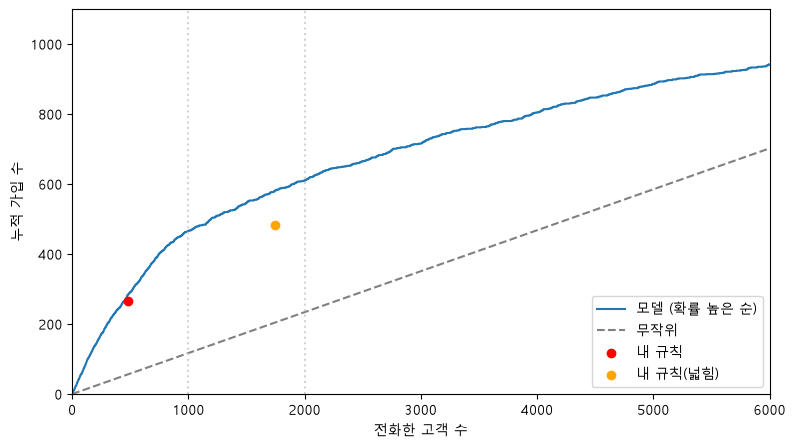

In [27]:
# [제공] 통화 예산 곡선
N_all = len(y_sorted)
x = np.arange(1, N_all + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
ax.scatter([rule_n], [rule_hits], color="red", zorder=5, label="내 규칙")
ax.scatter([wide_n], [wide_hits], color="orange", zorder=5, label="내 규칙(넓힘)")
for N in (1000, 2000):
    ax.axvline(N, color="lightgray", linestyle=":")
ax.set_xlim(0, 6000)
ax.set_ylim(0, 1100)
ax.set_xlabel("전화한 고객 수")
ax.set_ylabel("누적 가입 수")
ax.legend()
plt.show()

> **[판단]** 내 규칙의 두 점은 모델의 곡선과 비교해 어디에 있나요? 규칙을 넓혔을 때 점이 곡선에서 멀어졌나요, 가까워졌나요?
>
> 나의 답: 좁은 규칙(484명, 가입 265명)은 같은 인원의 곡선 값(285명)에서 20명 아래로, 곡선 가까이에 있습니다. 넓힌 규칙(1,748명, 가입 484명)은 곡선 값(582명)에서 98명 아래로 멀어졌습니다. 규칙을 넓히니 점이 곡선에서 멀어졌습니다.

## 4-3. 같은 수를 고른다면

규칙과 모델을 공정하게 비교하려면 **같은 수의 고객**을 골라야 합니다. 규칙이 `rule_n`명을 골랐다면, 모델도 상위 `rule_n`명만 고르면 됩니다.

**[직접 작성]** 모델이 확률 상위 `rule_n`명, 그리고 `wide_n`명을 골랐을 때 얻는 가입 수를 `model_at_rule`, `model_at_wide`에 저장하고, 규칙의 가입 수(`rule_hits`, `wide_hits`)와 나란히 출력하세요.

<details><summary>힌트</summary>

`cum_model[rule_n - 1]`입니다. ($N$명을 골랐을 때의 가입 수는 `cum_model`의 $N$번째 값입니다.)
</details>

In [28]:
# 4-3. 같은 인원을 골랐을 때 모델이 얻는 가입
model_at_rule = cum_model[rule_n - 1]
model_at_wide = cum_model[wide_n - 1]

print("나의 규칙:", rule_n, "명 → 규칙", rule_hits, "vs 모델", model_at_rule)
print("넓힌 규칙:", wide_n, "명 → 규칙", wide_hits, "vs 모델", model_at_wide)

나의 규칙: 484 명 → 규칙 265 vs 모델 285
넓힌 규칙: 1748 명 → 규칙 484 vs 모델 582


> **[판단]** 같은 수의 고객을 골랐을 때 모델이 내 규칙보다 가입을 몇 명 더(몇 배) 얻었나요? 규칙을 넓혔을 때 그 차이는 어떻게 달라졌나요?
>
> 나의 답: 같은 484명을 골랐을 때 모델은 285명으로 규칙(265명)보다 20명, 약 1.08배 많이 얻었습니다. 넓힌 뒤 같은 1,748명 기준으로는 582명 대 484명, 98명(약 1.2배) 차이입니다. 규칙을 넓히면 모델과의 차이가 절대 수로도 배수로도 커집니다.

## 4-4. 전화를 늘리면 가입은 얼마나 느는가

전화를 한 통씩 더 걸 때마다 얻는 가입은 줄어듭니다. 이 감소가 예산을 정하는 핵심입니다.

**[직접 작성]** 전화 수를 1,000 간격(1,000, 2,000, …, 6,000)으로 늘려 갈 때, **직전 구간보다 추가로 건 전화 1통당 얻는 가입 수**(추가 가입률)를 표로 출력하세요.

<details><summary>힌트</summary>

구간 `[a, b)`의 추가 가입 수는 `cum_model[b - 1] - cum_model[a - 1]`이고, 추가로 건 전화는 `b - a`통입니다. 첫 구간(0~1,000)은 `cum_model[999]`를 그대로 씁니다.
</details>

In [29]:
# 4-4. 구간별 추가 가입률
for a, b_ in [(0, 1000), (1000, 2000), (2000, 3000), (3000, 4000), (4000, 5000), (5000, 6000)]:
    add = cum_model[b_ - 1] - (cum_model[a - 1] if a > 0 else 0)
    print(f"{a}~{b_}통: 추가 가입 {add}명, 추가 가입률 {add / (b_ - a):.1%}")


0~1000통: 추가 가입 466명, 추가 가입률 46.6%
1000~2000통: 추가 가입 144명, 추가 가입률 14.4%
2000~3000통: 추가 가입 106명, 추가 가입률 10.6%
3000~4000통: 추가 가입 88명, 추가 가입률 8.8%
4000~5000통: 추가 가입 82명, 추가 가입률 8.2%
5000~6000통: 추가 가입 56명, 추가 가입률 5.6%


**가정**: 전화 한 통의 비용이 10달러이고, 가입 한 건이 은행에 주는 가치가 100달러라고 해 봅시다. (실제 값이 아니라 이 실습을 위한 가정입니다.) 이 경우 전화 한 통이 본전이 되려면 가입률이 **10% 이상**이어야 합니다.

> **[판단]** 위 가정이라면 어느 구간까지 전화를 걸어야 이득일까요? 표의 "추가 가입률"이 10% 밑으로 떨어지는 구간을 찾아 몇 통까지 걸지 정하고 이유를 적으세요. (1,000통이라는 제약은 잠시 잊습니다.)
>
> 나의 답: 1,000~2,000통 구간의 추가 가입률은 14.4%로 10%를 넘어 이득입니다. 2,000~3,000통은 10.6%로 아직 10% 위입니다. 3,000~4,000통은 8.8%로 10% 아래라 손해입니다. 따라서 약 3,000통까지 거는 것이 이득입니다. 계산으로도 확인하면, 1,000~2,000통은 가입 144명 × 100 = 14,400 대 비용 10,000으로 이득 4,400입니다. 2,000~3,000통은 106 × 100 = 10,600 대 10,000으로 이득 600이라 아슬아슬합니다. 3,000~4,000통은 88 × 100 = 8,800으로 비용에 못 미쳐 손해입니다.

> **[판단]** 의뢰서에는 1,000통이라는 제약이 있습니다. 위 가정에서 1,000통은 너무 적을까요, 충분할까요? 마케팅팀에 "통화 예산을 늘릴 만한가"를 어떻게 설명하겠습니까?
>
> 나의 답: 가정 아래에서 1,000통은 너무 적습니다. 1,000통에서 얻는 가입은 466명이지만, 1,000통을 더 걸면 144명을 더 얻어 비용보다 이득입니다. 마케팅팀에는 '통화 예산을 1,000통에서 약 3,000통으로 늘리면 가입이 466명에서 716명으로 약 250명 늘어난다. 처음 추가 1,000통은 이득이 크고, 그다음 1,000통은 본전 근처라 3,000통이 상한이다'라고 설명하겠습니다. 다만 비용과 가입 가치는 가정이므로 실제 값을 확인한 뒤 확정해야 합니다. 1,000통은 콜센터 제약이므로 그 제약을 풀 수 있는지도 먼저 물어봐야 합니다.

## 4-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

전화할 고객을 고르는 규칙은 나의 규칙 하나만 있는 것이 아닙니다. 다음 절에서는 1-5의 집계에서 본 조건들로 만들 수 있는 규칙을 모두 만들어 채점합니다. 조건은 성격이 다른 두 종류입니다.

| 종류 | 조건 | 특징 |
| --- | --- | --- |
| 강한 조건 | 이전 캠페인 성공(`poutcome` = success), 60세 초과, 25세 이하 | 해당 고객은 200~300명뿐이지만 가입률이 22~65%로 높다 |
| 넓은 조건 | 휴대전화 연락(`contact` = cellular), 주택 대출 없음(`housing` = no), 통화 2회 이하(`campaign` ≤ 2), 잔액 1,000 이상(`balance` ≥ 1,000) | 해당 고객이 수천 명이지만 가입률이 13~17%로 낮다 |

그래서 규칙도 두 가족으로 만듭니다. 2-1의 나의 규칙과 2-2의 넓힌 규칙이 바로 이 두 가족입니다.

- **좁은 규칙**: 강한 조건을 1~3개 "또는"으로 모은다 → 3 + 3 + 1 = 7개. 적은 인원을 고른다.
- **넓은 규칙**: 넓은 조건을 1~4개 "그리고"로 좁힌다 → 4 + 6 + 4 + 1 = 15개. 많은 인원을 고른다.

규칙마다 고르는 인원이 다르므로, 공정하게 비교하려면 **같은 인원을 고른 모델**과 비교합니다(4-3). 규칙이 625명을 골랐다면 모델도 확률 상위 625명을 고릅니다. 이때 규칙이 얻은 가입이 모델의 몇 %인지를 **규칙의 효율**이라고 부르겠습니다.

> **[판단]** 예상 ① 규칙 22개 중, 같은 인원을 골랐을 때 모델보다 가입을 더 많이 얻는(효율 100% 이상) 규칙이 있을까요? 있다면 어느 가족의 규칙일까요?
>
> 나의 답: 없을 것으로 예상합니다. 모델은 확률로 전체 고객을 세밀하게 줄 세우는데, 규칙은 조건으로 자른 덩어리라 같은 인원에서 모델을 넘기 어렵다고 생각합니다.

> **[판단]** 예상 ② 좁은 규칙과 넓은 규칙 중 어느 가족의 효율이 더 높을까요? 이유도 적어 보세요.
>
> 나의 답: 좁은 규칙 가족의 효율이 더 높을 것으로 예상합니다. 좁은 규칙은 가입률이 높은 고객(이전 캠페인 성공, 60세 초과 등)만 골라서 모델도 이 고객들을 위쪽에 잘 올려놓기 때문에 차이가 작을 것입니다. 넓은 규칙은 가입률이 13~17%로 고객들이 비슷해 순서를 줄 수 없어서 모델과 차이가 클 것입니다.

## 4-6. 규칙 22개 채점하기

**[직접 작성]** `my_rule_text`에 나의 규칙을 한 줄로 적으세요. 아래 결과에서 나의 규칙을 표시할 때 씁니다. (예: `"이전 캠페인 성공 또는 60세 초과"`)

In [30]:
my_rule_text = "이전 캠페인 성공 또는 60세 초과"

**[제공]** 좁은 규칙 7개와 넓은 규칙 15개를 만들고, 규칙마다 같은 인원을 고른 모델의 가입 수와 비교합니다.

In [31]:
# [제공] 좁은 규칙(강한 조건을 "또는"으로)과 넓은 규칙(넓은 조건을 "그리고"로)
from itertools import combinations

strong = {
    "이전 캠페인 성공": test_df["poutcome"] == "success",
    "60세 초과": test_df["age"] > 60,
    "25세 이하": test_df["age"] <= 25,
}
broad = {
    "휴대전화 연락": test_df["contact"] == "cellular",
    "주택 대출 없음": test_df["housing"] == "no",
    "통화 2회 이하": test_df["campaign"] <= 2,
    "잔액 1,000 이상": test_df["balance"] >= 1000,
}

candidates = []
for n in [1, 2, 3]:
    for combo in combinations(strong, n):
        candidates.append(("좁은 규칙", " 또는 ".join(combo), np.logical_or.reduce([strong[c] for c in combo])))
for n in [1, 2, 3, 4]:
    for combo in combinations(broad, n):
        candidates.append(("넓은 규칙", " 그리고 ".join(combo), np.logical_and.reduce([broad[c] for c in combo])))

rows = []
for family, name, mask in candidates:
    n_sel = int(mask.sum())
    hits = int(y_test[np.asarray(mask)].sum())
    model_hits = int(cum_model[n_sel - 1])
    rows.append({"가족": family, "규칙": name, "선정 인원": n_sel, "규칙 가입": hits,
                 "규칙 가입률": round(hits / n_sel, 3), "모델 가입 (같은 인원)": model_hits,
                 "효율": round(hits / model_hits, 2)})
rules = pd.DataFrame(rows).sort_values("효율", ascending=False, ignore_index=True)
print("만든 규칙 수:", len(rules))
rules

만든 규칙 수: 22


,가족,규칙,선정 인원,규칙 가입,규칙 가입률,모델 가입 (같은 인원),효율
0,좁은 규칙,이전 캠페인 성공,306,199,0.650,203,0.98
1,넓은 규칙,휴대전화 연락,5820,888,0.153,931,0.95
2,좁은 규칙,이전 캠페인 성공 또는 60세 초과,484,265,0.548,285,0.93
3,넓은 규칙,휴대전화 연락 그리고 통화 2회 이하,3910,677,0.173,795,0.85
4,넓은 규칙,통화 2회 이하,6000,798,0.133,942,0.85
5,넓은 규칙,주택 대출 없음,4095,679,0.166,815,0.83
6,넓은 규칙,휴대전화 연락 그리고 주택 대출 없음,2987,586,0.196,715,0.82
7,좁은 규칙,이전 캠페인 성공 또는 60세 초과 또는 25세 이하,727,312,0.429,390,0.80
8,좁은 규칙,이전 캠페인 성공 또는 25세 이하,549,246,0.448,313,0.79
9,넓은 규칙,주택 대출 없음 그리고 통화 2회 이하,2643,516,0.195,683,0.76


**[제공]** 규칙들의 점을 모델의 곡선 위에 그리고, 나의 규칙과 비교합니다.

효율 100% 이상(모델 이상)인 규칙: 0개 / 22개
나의 규칙 [이전 캠페인 성공 또는 60세 초과] 484명 선정 → 가입 265명 | 모델 같은 인원 → 가입 285명 | 효율 0.93
  나보다 효율이 높은 규칙: 3개

가족별 효율 중앙값:
가족
넓은 규칙    0.64
좁은 규칙    0.79
Name: 효율, dtype: float64

선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)
   가족                                                규칙  선정 인원  규칙 가입  규칙 가입률  모델 가입 (같은 인원)   효율
좁은 규칙                     이전 캠페인 성공 또는 60세 초과 또는 25세 이하    727    312   0.429            390 0.80
넓은 규칙                          주택 대출 없음 그리고 잔액 1,000 이상   1459    325   0.223            540 0.60
넓은 규칙              휴대전화 연락 그리고 주택 대출 없음 그리고 잔액 1,000 이상   1053    269   0.255            474 0.57
넓은 규칙              휴대전화 연락 그리고 통화 2회 이하 그리고 잔액 1,000 이상   1329    284   0.214            520 0.55
넓은 규칙             주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    951    244   0.257            456 0.54
넓은 규칙 휴대전화 연락 그리고 주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    703    205   0.292            379 0.54


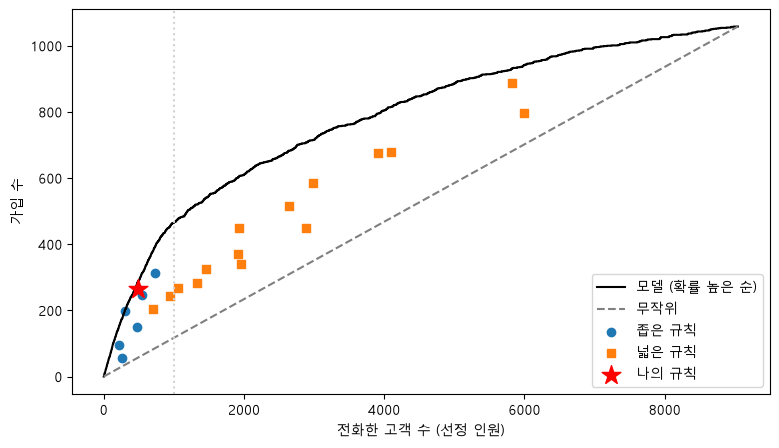

In [32]:
# [제공] 규칙들과 모델의 곡선
my_eff = rule_hits / cum_model[rule_n - 1]
print(f"효율 100% 이상(모델 이상)인 규칙: {(rules['효율'] >= 1).sum()}개 / {len(rules)}개")
print(f"나의 규칙 [{my_rule_text}] {rule_n:,}명 선정 → 가입 {rule_hits}명 | 모델 같은 인원 → 가입 {int(cum_model[rule_n - 1])}명 | 효율 {my_eff:.2f}")
print(f"  나보다 효율이 높은 규칙: {(rules['효율'] > my_eff).sum()}개")
print()
print("가족별 효율 중앙값:")
print(rules.groupby("가족")["효율"].median())
print()
print("선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)")
print(rules[rules["선정 인원"].between(700, 1500)].to_string(index=False))

x = np.arange(1, len(y_sorted) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, color="black", label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
for family, marker in [("좁은 규칙", "o"), ("넓은 규칙", "s")]:
    part = rules[rules["가족"] == family]
    ax.scatter(part["선정 인원"], part["규칙 가입"], marker=marker, label=family)
ax.scatter([rule_n], [rule_hits], color="red", s=200, marker="*", zorder=5, label="나의 규칙")
ax.axvline(1000, color="lightgray", linestyle=":")
ax.set_xlabel("전화한 고객 수 (선정 인원)")
ax.set_ylabel("가입 수")
ax.legend(loc="lower right")
plt.show()

## 4-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: 예상 ①은 맞았습니다. 효율 100% 이상인 규칙은 0개입니다. 예상 ②도 맞았습니다. 좁은 규칙의 중앙값은 0.79, 넓은 규칙은 0.64입니다. 가장 크게 빗나간 것은 넓은 규칙 중 '휴대전화 연락' 하나(5,820명)가 효율 0.95로 높게 나온 점입니다. 넓은 조건 하나가 모델에 이 정도로 가까울 줄은 예상하지 못했습니다. 이유는 인원이 많아질수록 모델의 추가 가입률도 낮아져 누적 곡선이 평평해지고, 같은 인원끼리 비교하면 격차가 줄기 때문입니다. 즉 '넓은 규칙은 나쁘다'가 아니라 '넓은 규칙은 인원이 많을 때만 모델과 비슷하다'가 맞습니다.

> **[판단]** 좁은 규칙과 넓은 규칙의 효율은 어떻게 다른가요? 그림에서 두 가족의 점이 모델의 곡선과 얼마나 떨어져 있는지와 연결해 설명해 보세요. 넓은 규칙에 조건을 "그리고"로 더할수록 효율은 어떻게 변하나요?
>
> 나의 답: 좁은 규칙의 점들은 모델 곡선에 가깝습니다(중앙값 0.79, 최고 306명 규칙 0.98). 넓은 규칙은 곡선에서 더 떨어져 있습니다(중앙값 0.64). 넓은 규칙에 '그리고'로 조건을 더할수록 효율이 떨어집니다. 조건 1개(휴대전화 연락)는 0.95, 2개 조합은 0.56~0.85, 3~4개 조합은 0.54~0.74입니다. 조건이 늘면 인원은 줄고 가입률은 14~25% 사이에 몰려서 모델이 잘 줄 세운 고객과의 차이가 커집니다.

> **[판단]** 1,000통 제약에 가까운 규칙(선정 700~1,500명)은 가입을 몇 명 얻나요? 같은 인원을 고른 모델과 비교하면 몇 배인가요? 마케팅팀이 규칙 대신 모델을 쓸 이유가 충분한가요?
>
> 나의 답: 700~1,500명 규칙은 가입 205~325명을 얻습니다(예: 727명 규칙 312명). 같은 인원을 고른 모델은 379~540명을 얻어 약 1.3~1.9배입니다. 모델이 1,000명에서 얻은 466명과 비교해도 규칙 최고치(312명)는 약 2/3 수준입니다. 마케팅팀이 규칙 대신 모델을 쓸 이유는 충분합니다. 모델은 순위를 매겨 원하는 인원(1,000명, 2,000명)을 정확히 고를 수 있지만, 규칙은 인원을 맞추기 어렵기 때문입니다.

> **[판단]** 나의 규칙은 규칙들 사이에서 어디쯤인가요? 좁은 규칙과 넓은 규칙을 "또는"으로 합치면(예: 이전 캠페인 성공 또는 주택 대출 없음 그리고 잔액 1,000 이상) 선정 인원과 효율이 어떻게 될지 예상해 보세요. 이렇게 규칙을 손으로 조합해 가는 일과, 모델이 확률로 순서를 매기는 일은 무엇이 다른가요?
>
> 나의 답: 나의 규칙은 22개 중 전체 3위(효율 0.93)이고, 좁은 규칙 중에서는 '이전 캠페인 성공'(0.98)에 이어 2위입니다. 좁은 규칙 두 개를 '또는'으로 합치면(이전 캠페인 성공 또는 주택 대출 없음 그리고 잔액 1,000 이상) 두 집합의 합이라 인원은 약 1,500~1,800명 사이가 될 것으로 예상합니다. 효율은 넓은 규칙 쪽의 영향으로 0.6~0.8 정도로 떨어질 것으로 예상합니다. 손으로 조합하는 일은 조건을 하나씩 골라 인원과 효율을 확인해야 하고, 조합이 늘수록 사람이 다 살펴보기 어렵습니다. 모델은 모든 고객에게 확률을 주고 순서를 한 번에 매기므로, 어떤 인원이든 같은 기준으로 고를 수 있습니다.

## 4-8. 마케팅팀 보고 메모

분석 결과를 마케팅팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **누구에게 전화해야 하는가**: 선정 방식(예: 가입 가능성이 높은 순서대로 $N$명)을 한 문장으로 쓴다
2. **예산별 기대 가입**: 1,000통과 2,000통일 때 기대할 수 있는 가입 수를 쓰고, 현재 쓰는 방법(내 규칙)과 비교한다
3. **권고**: 몇 통을 걸 것을 권하는지, 4-4에서 가정한 비용 구조를 밝히고 이유를 쓴다
4. **주의할 점**: 통화 시간 열을 뺀 이유를 아직 확인하지 못했다는 것(Chapter 4 예고), 통화 수가 적은 집단 규칙의 불확실성, 이 데이터는 2008~2010년 포르투갈 은행의 것이라는 점

> **[판단]** 마케팅팀 보고 메모:
>
> 1. 선정 방식: 고객마다 가입 가능성을 모델로 계산해, 가입 가능성이 높은 고객부터 순서대로 전화합니다.
>
> 2. 예산별 기대 가입: 평가 데이터(9,043명 중 1,000통 기준) 기준, 1,000통이면 약 466명, 2,000통이면 약 610명이 가입합니다(무작위 대비 약 4배). 현재 쓰는 방법(조건 규칙, 484명 선정)은 265명이고, 같은 인원이면 모델은 285명입니다. 규칙을 넓힌 방법(1,748명 선정)은 484명이고, 같은 인원이면 모델은 582명입니다.
>
> 3. 권고와 이유(가정한 비용 구조 포함): 전화 1통 10달러, 가입 1건 가치 100달러라는 가정에서는 약 3,000통까지 거는 것을 권합니다. 2,000~3,000통 구간은 가입 106명(추가 가입률 10.6%)으로 아직 이득이고, 3,000통 이후는 손해입니다. 1,000통 안에서는 모델 순서대로 1,000명을 거는 것이 현재 방법보다 가입을 늘립니다. 실제 비용과 가치를 받으면 이 기준을 다시 계산해야 합니다.
>
> 4. 주의할 점: 통화 시간(duration) 열은 통화가 끝나야 알 수 있는 정보라 이번 분석에서 뺐습니다. 이 열을 넣으면 점수가 좋아지는 이유는 아직 확인하지 못했고, Chapter 4에서 다룹니다. 3월(391명)처럼 통화 수가 적은 집단의 가입률은 오차가 커서(±5%p 안팎) 규칙 근거로는 불확실합니다. 이 데이터는 2008~2010년 포르투갈 은행의 것이라 지금 시장에 그대로 적용하기 어렵습니다.
>
> 나의 답:

---
# 마무리

## 이 Chapter의 판단 포인트

> **놓친 가입 고객과 헛걸음한 전화 중 무엇이 더 비싼가? 임계값은 모델이 아니라 비용이 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "분류 모델의 점수를 보면 임계값과 혼동행렬을 먼저 묻고, 같은 수를 고른 현행 규칙과 비교한다."

> **[판단]** 나의 체크리스트 4번(분류 모델의 점수를 볼 때):
>
> 나의 답: 분류 모델의 점수를 볼 때는 정확도부터 보지 않고, 먼저 혼동행렬과 임계값별 정밀도·재현율을 확인합니다. 그다음 같은 인원을 고른 현행 방법(규칙)과 비교합니다. 이번 실습에서 정확도 89.3%는 베이스라인 88.3%와 거의 차이가 없었습니다.

> **[판단]** 나의 체크리스트 5번(양성 비율이 낮은 문제에서 정확도를 볼 때):
>
> 나의 답: 양성 비율이 낮은 문제에서는 정확도를 보기 전에 '전부 음성'을 찍는 베이스라인의 정확도를 먼저 계산합니다. 이 값이 높으면(여기서는 88.3%) 정확도는 의미가 거의 없으므로 정밀도·재현율·PR AUC를 같이 봅니다.

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 4에서는 이번에 일부러 뺀 통화 시간 열을 넣으면 왜 점수가 갑자기 좋아지는지, 그리고 그 점수를 믿어도 되는지를 배웁니다.